In [1]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path

from tensorflow.keras import layers, models, regularizers

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seeds configured.")

Random seeds configured.


In [3]:
from google.colab import drive


drive.mount("/content/drive")
print("Google Drive connected successfully.")

Mounted at /content/drive
Google Drive connected successfully.


In [4]:
PROJECT_DIR = "/content/drive/MyDrive/Nexar_Project"

DATASET_DIR = os.path.join(
    PROJECT_DIR,
    "Dataset_2FPS"
)

POSITIVE_DIR = os.path.join(
    DATASET_DIR,
    "positive"
)

NEGATIVE_DIR = os.path.join(
    DATASET_DIR,
    "negative"
)

MANIFEST_DIR = os.path.join(
    PROJECT_DIR,
    "Manifests"
)

TRAIN_MANIFEST = os.path.join(
    MANIFEST_DIR,
    "train_manifest.csv"
)

VAL_MANIFEST = os.path.join(
    MANIFEST_DIR,
    "validation_manifest.csv"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "Models"
)

EXPERIMENT_NAME = "mobilenetv2_bigru_16frames_augmented"

EXPERIMENT_DIR = os.path.join(
    MODEL_DIR,
    EXPERIMENT_NAME
)

os.makedirs(EXPERIMENT_DIR, exist_ok=True)

print("Project paths configured successfully.")

Project paths configured successfully.


In [5]:
required_paths = {
    "Project": PROJECT_DIR,
    "Positive Dataset": POSITIVE_DIR,
    "Negative Dataset": NEGATIVE_DIR,
    "Train Manifest": TRAIN_MANIFEST,
    "Validation Manifest": VAL_MANIFEST
}

for name, path in required_paths.items():

    exists = os.path.exists(path)

    print(f"{name}: {exists}")

    if not exists:
        raise FileNotFoundError(
            f"Required path not found: {path}"
        )

Project: True
Positive Dataset: True
Negative Dataset: True
Train Manifest: True
Validation Manifest: True


In [6]:
train_df = pd.read_csv(TRAIN_MANIFEST)

validation_df = pd.read_csv(VAL_MANIFEST)

for df in [train_df, validation_df]:

    if "label" not in df.columns and "target" in df.columns:
        df.rename(
            columns={"target": "label"},
            inplace=True
        )

    if "file_name" not in df.columns and "id" in df.columns:
        df["file_name"] = df["id"].astype(str)

    if "label" not in df.columns:
        raise ValueError("Missing label column.")

    if "file_name" not in df.columns:
        raise ValueError("Missing file_name column.")

print("Train samples:", len(train_df))
print("Validation samples:", len(validation_df))

print("\nTrain distribution:")
print(train_df["label"].value_counts())

print("\nValidation distribution:")
print(validation_df["label"].value_counts())

Train samples: 1200
Validation samples: 300

Train distribution:
label
1    600
0    600
Name: count, dtype: int64

Validation distribution:
label
0    150
1    150
Name: count, dtype: int64


In [7]:
SEQUENCE_LENGTH = 16

IMAGE_HEIGHT = 224
IMAGE_WIDTH = 224
CHANNELS = 3

MODEL_IMAGE_SIZE = 160

BATCH_SIZE = 1

AUTOTUNE = tf.data.AUTOTUNE

print("Video configuration completed.")

Video configuration completed.


In [8]:
AUGMENTATION_ENABLED = True

BRIGHTNESS_DELTA = 20.0

CONTRAST_MIN = 0.90
CONTRAST_MAX = 1.10

HORIZONTAL_FLIP_PROBABILITY = 0.50

print("Data augmentation configuration completed.")

Data augmentation configuration completed.


In [25]:
def augment_video(
    frames,
    brightness_delta=20.0,
    contrast_range=(0.90, 1.10),
    force_flip=None,
    return_info=False
):
    frames = np.asarray(frames, dtype=np.float32).copy()

    # 1. Random brightness
    brightness = np.random.uniform(
        -brightness_delta,
        brightness_delta
    )

    frames += brightness

    # 2. Random contrast
    contrast = np.random.uniform(
        contrast_range[0],
        contrast_range[1]
    )

    mean = np.mean(frames, axis=(0, 1, 2), keepdims=True)

    frames = (frames - mean) * contrast + mean

    # 3. Random horizontal flip
    if force_flip is None:
        horizontal_flip = np.random.random() < 0.5
    else:
        horizontal_flip = force_flip

    if horizontal_flip:
        frames = np.flip(frames, axis=2)

    # 4. Keep pixel values in valid range
    frames = np.clip(frames, 0, 255)

    frames = frames.astype(np.float32)

    if return_info:
        info = {
            "brightness": float(brightness),
            "contrast": float(contrast),
            "horizontal_flip": bool(horizontal_flip)
        }

        return frames, info

    return frames

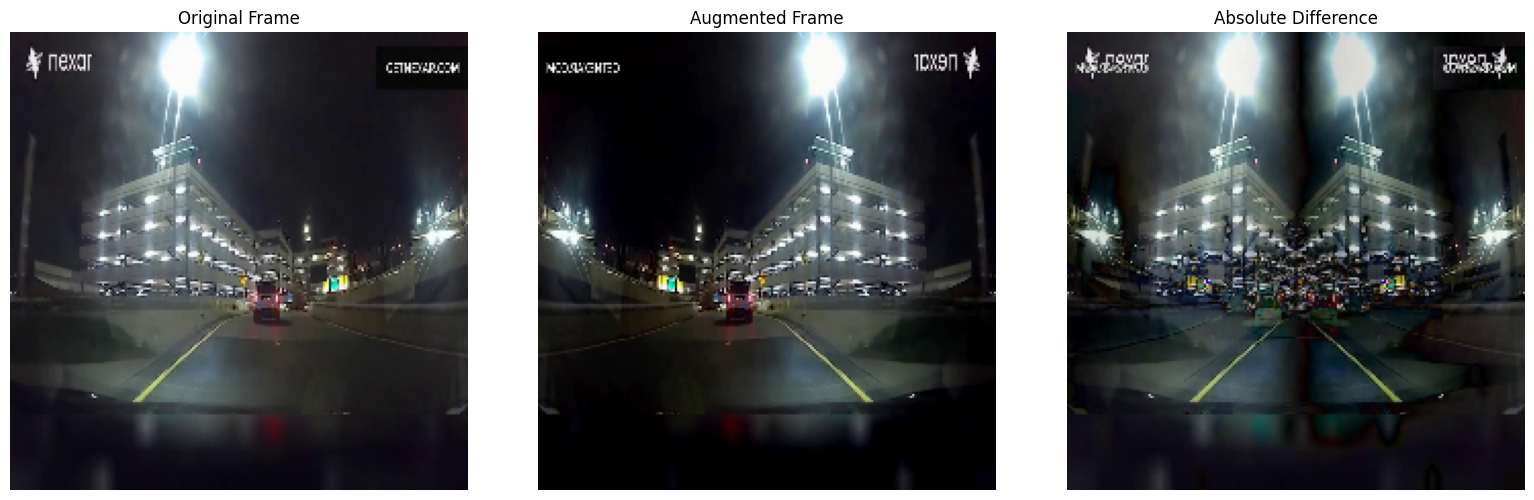

Augmentation parameters:
brightness: 3.946339367881464
contrast: 0.9312037280884873
horizontal_flip: True
Mean pixel difference: 54.59715136054422


In [27]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Select a sample
sample_row = train_df.iloc[0]

sample_label = float(sample_row["label"])

sample_folder = (
    POSITIVE_DIR
    if sample_label == 1
    else NEGATIVE_DIR
)

sample_name = os.path.splitext(
    str(sample_row["file_name"])
)[0]

sample_path = os.path.join(
    sample_folder,
    sample_name + ".npz"
)

# Check file
if not os.path.exists(sample_path):
    raise FileNotFoundError(sample_path)

# Load frames
with np.load(sample_path) as data:
    original_frames = data["frames"][:16]

# Apply augmentation
augmented_frames = augment_video(
    original_frames,
    force_flip=True
)

# Select frame
frame_index = 8

original = original_frames[frame_index].astype(np.uint8)

augmented = augmented_frames[frame_index].astype(np.uint8)

difference = np.abs(
    original.astype(np.int16) -
    augmented.astype(np.int16)
).astype(np.uint8)

# Display
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original Frame")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(augmented)
plt.title("Augmented Frame")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(difference)
plt.title("Absolute Difference")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Augmentation parameters:")

for key, value in augmentation_info.items():
    print(f"{key}: {value}")

print("Mean pixel difference:", np.mean(difference))

In [28]:
def prepare_video(
    npz_path,
    sequence_length=SEQUENCE_LENGTH
):

    with np.load(npz_path) as data:

        frames = data["frames"]

    total_frames = len(frames)

    if total_frames == 0:

        raise ValueError(
            f"Empty video: {npz_path}"
        )

    if total_frames >= sequence_length:

        indices = np.linspace(
            0,
            total_frames - 1,
            sequence_length
        ).astype(int)

        selected_frames = frames[indices]

        mask = np.ones(
            sequence_length,
            dtype=bool
        )

    else:

        selected_frames = np.zeros(
            (
                sequence_length,
                IMAGE_HEIGHT,
                IMAGE_WIDTH,
                CHANNELS
            ),
            dtype=np.float32
        )

        selected_frames[:total_frames] = frames

        selected_frames[total_frames:] = frames[-1]

        mask = np.zeros(
            sequence_length,
            dtype=bool
        )

        mask[:total_frames] = True

    return (
        selected_frames.astype(np.float32),
        mask
    )

In [29]:
def normalize_label(value):

    if isinstance(value, str):

        value = value.strip().lower()

        if value in ["positive", "pos", "1"]:
            return 1.0

        if value in ["negative", "neg", "0"]:
            return 0.0

    value = float(value)

    if value not in [0.0, 1.0]:
        raise ValueError(f"Invalid label: {value}")

    return value


def resolve_npz_path(file_name, label):

    label = normalize_label(label)

    folder = (
        POSITIVE_DIR
        if label == 1.0
        else NEGATIVE_DIR
    )

    file_stem = Path(
        str(file_name)
    ).stem

    npz_path = os.path.join(
        folder,
        file_stem + ".npz"
    )

    if not os.path.isfile(npz_path):

        raise FileNotFoundError(
            f"NPZ file not found: {npz_path}"
        )

    return npz_path


print("Video path and label functions created.")

Video path and label functions created.


In [30]:
def data_generator(
    dataframe,
    training=False,
    shuffle=False
):

    df = dataframe.copy()

    if shuffle:

        df = df.sample(
            frac=1,
            random_state=np.random.randint(0, 1_000_000)
        ).reset_index(drop=True)

    for _, row in df.iterrows():

        label = normalize_label(
            row["label"]
        )

        npz_path = resolve_npz_path(
            row["file_name"],
            label
        )

        frames, mask = prepare_video(
            npz_path
        )

        if training and AUGMENTATION_ENABLED:

            frames = augment_video(
                frames
            )

        inputs = {

            "video_input": frames,

            "mask_input": mask

        }

        yield (
            inputs,
            np.float32(label)
        )


print("Data generator created successfully.")

Data generator created successfully.


In [31]:
output_signature = (

    {

        "video_input": tf.TensorSpec(

            shape=(
                SEQUENCE_LENGTH,
                IMAGE_HEIGHT,
                IMAGE_WIDTH,
                CHANNELS
            ),

            dtype=tf.float32

        ),

        "mask_input": tf.TensorSpec(

            shape=(SEQUENCE_LENGTH,),

            dtype=tf.bool

        )

    },

    tf.TensorSpec(

        shape=(),

        dtype=tf.float32

    )

)

print("Output signature configured.")

Output signature configured.


In [32]:
train_dataset = tf.data.Dataset.from_generator(

    lambda: data_generator(
        train_df,
        training=True,
        shuffle=True
    ),

    output_signature=output_signature

)

train_eval_dataset = tf.data.Dataset.from_generator(

    lambda: data_generator(
        train_df,
        training=False,
        shuffle=False
    ),

    output_signature=output_signature

)

validation_dataset = tf.data.Dataset.from_generator(

    lambda: data_generator(
        validation_df,
        training=False,
        shuffle=False
    ),

    output_signature=output_signature

)


train_dataset = (

    train_dataset
    .repeat()
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)

)

train_eval_dataset = (

    train_eval_dataset
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)

)

validation_dataset = (

    validation_dataset
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)

)


print("All datasets created successfully.")

All datasets created successfully.


In [33]:
base_model = tf.keras.applications.MobileNetV2(

    weights="imagenet",

    include_top=False,

    pooling="avg",

    input_shape=(
        MODEL_IMAGE_SIZE,
        MODEL_IMAGE_SIZE,
        CHANNELS
    )

)

base_model.trainable = False

print("MobileNetV2 loaded successfully.")
print("Backbone trainable:", base_model.trainable)

MobileNetV2 loaded successfully.
Backbone trainable: False


In [34]:
# Video input
video_input = layers.Input(

    shape=(
        SEQUENCE_LENGTH,
        IMAGE_HEIGHT,
        IMAGE_WIDTH,
        CHANNELS
    ),

    name="video_input"

)

# Mask input
mask_input = layers.Input(

    shape=(SEQUENCE_LENGTH,),

    dtype=tf.bool,

    name="mask_input"

)

# Resize frames
x = layers.TimeDistributed(

    layers.Resizing(
        MODEL_IMAGE_SIZE,
        MODEL_IMAGE_SIZE
    ),

    name="frame_resize"

)(video_input)

# Normalize to [-1, 1]
x = layers.TimeDistributed(

    layers.Rescaling(
        scale=1.0 / 127.5,
        offset=-1.0
    ),

    name="frame_normalization"

)(x)

# Extract spatial features
x = layers.TimeDistributed(

    base_model,

    name="feature_extraction"

)(x)

# Normalize features
x = layers.LayerNormalization(

    name="feature_normalization"

)(x)

# Dropout before temporal learning
x = layers.Dropout(

    0.20,

    name="temporal_input_dropout"

)(x)

# Bidirectional GRU
x = layers.Bidirectional(

    layers.GRU(

        32,

        dropout=0.20,

        recurrent_dropout=0.0,

        return_sequences=False

    ),

    name="bidirectional_gru"

)(

    x,

    mask=mask_input

)

# Temporal normalization
x = layers.LayerNormalization(

    name="temporal_normalization"

)(x)

# Stronger dropout
x = layers.Dropout(

    0.40,

    name="gru_dropout"

)(x)

# Smaller dense layer + L2
x = layers.Dense(

    32,

    activation="relu",

    kernel_regularizer=regularizers.l2(1e-4),

    name="dense_features"

)(x)

x = layers.LayerNormalization(

    name="dense_normalization"

)(x)

# Final dropout
x = layers.Dropout(

    0.40,

    name="classifier_dropout"

)(x)

# Binary output
output = layers.Dense(

    1,

    activation="sigmoid",

    dtype="float32",

    name="collision_prediction"

)(x)

# Build model
model = models.Model(

    inputs={
        "video_input": video_input,
        "mask_input": mask_input
    },

    outputs=output,

    name="MobileNetV2_BiGRU_16Frames_Augmented"

)

model.summary()

Model: "MobileNetV2_BiGRU_16Frames_Augmented"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ video_input         │ (None, 16, 224,   │          0 │ -                 │
│ (InputLayer)        │ 224, 3)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ frame_resize        │ (None, 16, 160,   │          0 │ video_input[0][0] │
│ (TimeDistributed)   │ 160, 3)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ frame_normalization │ (None, 16, 160,   │          0 │ frame_resize[0][… │
│ (TimeDistributed)   │ 160, 3)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_extraction  │ (None, 16, 1280)  │  2,257,984 │ frame_normalizat… │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_normalizat… │ (None, 16, 1280)  │      2,560 │ feature_extracti… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_input_dro… │ (None, 16, 1280)  │          0 │ feature_normaliz… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mask_input          │ (None, 16)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_gru   │ (None, 64)        │    252,288 │ temporal_input_d… │
│ (Bidirectional)     │                   │            │ mask_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_normaliza… │ (None, 64)        │        128 │ bidirectional_gr… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_dropout         │ (None, 64)        │          0 │ temporal_normali… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_features      │ (None, 32)        │      2,080 │ gru_dropout[0][0] │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_normalization │ (None, 32)        │         64 │ dense_features[0… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dropout  │ (None, 32)        │          0 │ dense_normalizat… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ collision_predicti… │ (None, 1)         │         33 │ classifier_dropo… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,515,137 (9.59 MB)

 Trainable params: 257,153 (1004.50 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [35]:
LEARNING_RATE = 1e-4

model.compile(

    optimizer=tf.keras.optimizers.Adam(

        learning_rate=LEARNING_RATE

    ),

    loss="binary_crossentropy",

    metrics=[

        tf.keras.metrics.BinaryAccuracy(
            name="accuracy"
        ),

        tf.keras.metrics.Precision(
            name="precision"
        ),

        tf.keras.metrics.Recall(
            name="recall"
        ),

        tf.keras.metrics.AUC(
            name="auc"
        )

    ]

)

print("Model compiled successfully.")

Model compiled successfully.


In [36]:
EPOCHS = 10

BEST_MODEL_PATH = os.path.join(
    EXPERIMENT_DIR,
    "best_model.keras"
)

FINAL_MODEL_PATH = os.path.join(
    EXPERIMENT_DIR,
    "final_model.keras"
)

CSV_LOG_PATH = os.path.join(
    EXPERIMENT_DIR,
    "training_history.csv"
)

callbacks = [

    tf.keras.callbacks.ModelCheckpoint(

        filepath=BEST_MODEL_PATH,

        monitor="val_loss",

        save_best_only=True,

        mode="min",

        verbose=1

    ),

    tf.keras.callbacks.ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=2,

        min_lr=1e-6,

        verbose=1

    ),

    tf.keras.callbacks.EarlyStopping(

        monitor="val_loss",

        patience=4,

        restore_best_weights=True,

        verbose=1

    ),

    tf.keras.callbacks.CSVLogger(

        CSV_LOG_PATH

    )

]

print("Callbacks configured successfully.")

Callbacks configured successfully.


In [37]:
steps_per_epoch = len(train_df)

validation_steps = len(validation_df)

print("Training samples:", len(train_df))
print("Validation samples:", len(validation_df))

print("Steps per epoch:", steps_per_epoch)
print("Validation steps:", validation_steps)

Training samples: 1200
Validation samples: 300
Steps per epoch: 1200
Validation steps: 300


In [ ]:
history = model.fit(
    train_dataset,
    epochs=EPOCHS,
    steps_per_epoch=steps_per_epoch,
    validation_data=validation_dataset,
    validation_steps=validation_steps,
    callbacks=callbacks,
    verbose=1

)

Epoch 1/10
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 0s 893ms/step - accuracy: 0.5410 - auc: 0.5548 - loss: 0.8796 - precision: 0.5696 - recall: 0.5402
Epoch 1: val_loss improved from None to 0.54260, saving model to /content/drive/MyDrive/Nexar_Project/Models/mobilenetv2_bigru_16frames_augmented/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Nexar_Project/Models/mobilenetv2_bigru_16frames_augmented/best_model.keras
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 1416s 1s/step - accuracy: 0.5692 - auc: 0.5969 - loss: 0.8005 - precision: 0.5695 - recall: 0.5667 - val_accuracy: 0.7300 - val_auc: 0.8068 - val_loss: 0.5426 - val_precision: 0.7285 - val_recall: 0.7333 - learning_rate: 1.0000e-04
Epoch 2/10
 746/1200 ━━━━━━━━━━━━━━━━━━━━ 4:52 645ms/step - accuracy: 0.6132 - auc: 0.6761 - loss: 0.6726 - precision: 0.5774 - recall: 0.5895

In [ ]:
history_df = pd.DataFrame(history.history)

history_df.index = range(
    1,
    len(history_df) + 1
)

history_df.index.name = "Epoch"

display(history_df.round(4))

In [ ]:
epochs_range = range(
    1,
    len(history.history["loss"]) + 1
)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.xticks(list(epochs_range))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Crossentropy Loss")

plt.xticks(list(epochs_range))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()